# Inverted Index

The text files are placed in folder './iitfidf', i.e. we have three files in the folder: 1.txt, 2.txt, 3.txt

The **wholeTextFiles** will read the files, and output a tuple (filename, fulltext)

wholeTextFiles -> (filename, fulltext)

In the first step (flatMap), we map our existing key/value pair (filename, fulltext) to a new key-value pair comprising of document-id (i,e, filename) and token (each word in the fulltext) as the key and 1 (representing count) as the value. We will be using the flatMap transformation here to combine all the tokens in a single list.

 flatMap -> ((filename, token), 1)

In the second step (reduceByKey), we will be grouping the key/value pairs with the common key and further aggregate the values for the same key to get the term frequency for a particular word corresponding to its filename.

reduceByKey -> ((filename, token), 1+1+1...)

In the third step, we will change the key/value pairs to a new set of key/ value/pairs with tokens as the key and its filename and respective term frequency as the values.

map -> (token, (filename, count)), notice the count here is also called "Term Frequency"

In [1]:
from pyspark import SparkConf, SparkContext
import os, re

sc = SparkContext.getOrCreate(SparkConf())

In [2]:

inverted_index = sc.wholeTextFiles('data/iitfidf')\
                .flatMap(lambda x: [((os.path.basename(x[0]),i.lower()), 1) for i in re.split('\W+', x[1])])\
                .reduceByKey(lambda a, b: a + b)\
                .map(lambda x: (x[0][1],(x[0][0],x[1])))\
                .filter(lambda x: x[0] !='')\
                .reduceByKey(lambda a, b: a + b)\
                .sortByKey()

output = inverted_index.take(20)
for i in range(20):
    print(output[i])

#inverted_index.saveAsTextFile('large_txt')


('a', ('2.txt', 2, '3.txt', 1))
('all', ('2.txt', 1))
('alliance', ('2.txt', 1))
('and', ('1.txt', 2, '2.txt', 3, '3.txt', 2))
('antagonisms', ('3.txt', 2))
('are', ('1.txt', 1))
('as', ('3.txt', 1))
('away', ('3.txt', 1))
('bourgeois', ('3.txt', 1))
('bourgeoisie', ('3.txt', 2))
('but', ('3.txt', 1))
('camps', ('3.txt', 1))
('cats', ('1.txt', 1))
('class', ('3.txt', 2))
('classes', ('3.txt', 2))
('communism', ('2.txt', 1))
('conditions', ('3.txt', 1))
('czar', ('2.txt', 1))
('directly', ('3.txt', 1))
('distinctive', ('3.txt', 1))


In [4]:
#wholeTextFiles -> (filename, fulltext)
rdd1=sc.wholeTextFiles('data/iitfidf')

#flatMap -> ((filename, token), 1)
#rdd2 = rdd1.flatMap(lambda x: [((os.path.basename(x[0]).split(".")[0] ,i) ,1) for i in re.split('\W', x[1])])
rdd2 = rdd1.flatMap(lambda x: [((os.path.basename(x[0]), i.lower()), 1) for i in re.split('\W+', x[1])])
    
#rdd2.take(10)
rdd2.collect()

[(('1.txt', 'knitting'), 1),
 (('1.txt', 'is'), 1),
 (('1.txt', 'my'), 1),
 (('1.txt', 'hobby'), 1),
 (('1.txt', 'and'), 1),
 (('1.txt', 'my'), 1),
 (('1.txt', 'passion'), 1),
 (('1.txt', 'i'), 1),
 (('1.txt', 'love'), 1),
 (('1.txt', 'dogs'), 1),
 (('1.txt', 'and'), 1),
 (('1.txt', 'cats'), 1),
 (('1.txt', 'these'), 1),
 (('1.txt', 'are'), 1),
 (('1.txt', 'my'), 1),
 (('1.txt', 'love'), 1),
 (('2.txt', 'a'), 1),
 (('2.txt', 'spectre'), 1),
 (('2.txt', 'is'), 1),
 (('2.txt', 'haunting'), 1),
 (('2.txt', 'europe'), 1),
 (('2.txt', 'the'), 1),
 (('2.txt', 'spectre'), 1),
 (('2.txt', 'of'), 1),
 (('2.txt', 'communism'), 1),
 (('2.txt', 'all'), 1),
 (('2.txt', 'the'), 1),
 (('2.txt', 'powers'), 1),
 (('2.txt', 'of'), 1),
 (('2.txt', 'old'), 1),
 (('2.txt', 'europe'), 1),
 (('2.txt', 'have'), 1),
 (('2.txt', 'entered'), 1),
 (('2.txt', 'into'), 1),
 (('2.txt', 'a'), 1),
 (('2.txt', 'holy'), 1),
 (('2.txt', 'alliance'), 1),
 (('2.txt', 'to'), 1),
 (('2.txt', 'exorcise'), 1),
 (('2.txt', 'thi

In [6]:
#reduceByKey -> ((filename, token), 1+1+1...)
rdd3 = rdd2.reduceByKey(lambda a, b: a + b)
#output = rdd3.collect()
#for i in range(rdd3.count()):
#    print(output[i])
rdd3.collect()


[(('1.txt', 'knitting'), 1),
 (('1.txt', 'is'), 1),
 (('1.txt', 'my'), 3),
 (('1.txt', 'hobby'), 1),
 (('1.txt', 'and'), 2),
 (('1.txt', 'passion'), 1),
 (('1.txt', 'i'), 1),
 (('1.txt', 'love'), 2),
 (('1.txt', 'dogs'), 1),
 (('1.txt', 'cats'), 1),
 (('1.txt', 'these'), 1),
 (('1.txt', 'are'), 1),
 (('2.txt', 'a'), 2),
 (('2.txt', 'spectre'), 3),
 (('2.txt', 'is'), 1),
 (('2.txt', 'haunting'), 1),
 (('2.txt', 'europe'), 2),
 (('2.txt', 'the'), 2),
 (('2.txt', 'of'), 2),
 (('2.txt', 'communism'), 1),
 (('2.txt', 'all'), 1),
 (('2.txt', 'powers'), 1),
 (('2.txt', 'old'), 1),
 (('2.txt', 'have'), 1),
 (('2.txt', 'entered'), 1),
 (('2.txt', 'into'), 1),
 (('2.txt', 'holy'), 1),
 (('2.txt', 'alliance'), 1),
 (('2.txt', 'to'), 1),
 (('2.txt', 'exorcise'), 1),
 (('2.txt', 'this'), 1),
 (('2.txt', 'pope'), 1),
 (('2.txt', 'and'), 3),
 (('2.txt', 'czar'), 1),
 (('2.txt', 'metternich'), 1),
 (('2.txt', 'guizot'), 1),
 (('2.txt', 'french'), 1),
 (('2.txt', 'radicals'), 1),
 (('2.txt', 'german'),

In [7]:
# map -> (token, (filename, count))
inverted_index = rdd3.map(lambda x: (x[0][1],(x[0][0],x[1]))).filter(lambda x: x[0] !='')
inverted_index.collect()
#output = inverted_index.collect()
#for i in range(inverted_index.count()):
#    print(output[i])
    


[('knitting', ('1.txt', 1)),
 ('is', ('1.txt', 1)),
 ('my', ('1.txt', 3)),
 ('hobby', ('1.txt', 1)),
 ('and', ('1.txt', 2)),
 ('passion', ('1.txt', 1)),
 ('i', ('1.txt', 1)),
 ('love', ('1.txt', 2)),
 ('dogs', ('1.txt', 1)),
 ('cats', ('1.txt', 1)),
 ('these', ('1.txt', 1)),
 ('are', ('1.txt', 1)),
 ('a', ('2.txt', 2)),
 ('spectre', ('2.txt', 3)),
 ('is', ('2.txt', 1)),
 ('haunting', ('2.txt', 1)),
 ('europe', ('2.txt', 2)),
 ('the', ('2.txt', 2)),
 ('of', ('2.txt', 2)),
 ('communism', ('2.txt', 1)),
 ('all', ('2.txt', 1)),
 ('powers', ('2.txt', 1)),
 ('old', ('2.txt', 1)),
 ('have', ('2.txt', 1)),
 ('entered', ('2.txt', 1)),
 ('into', ('2.txt', 1)),
 ('holy', ('2.txt', 1)),
 ('alliance', ('2.txt', 1)),
 ('to', ('2.txt', 1)),
 ('exorcise', ('2.txt', 1)),
 ('this', ('2.txt', 1)),
 ('pope', ('2.txt', 1)),
 ('and', ('2.txt', 3)),
 ('czar', ('2.txt', 1)),
 ('metternich', ('2.txt', 1)),
 ('guizot', ('2.txt', 1)),
 ('french', ('2.txt', 1)),
 ('radicals', ('2.txt', 1)),
 ('german', ('2.txt', 

In [9]:

counts = inverted_index.reduceByKey(lambda a, b: a + b)
counts = counts.sortByKey()
counts.collect()

[('a', ('2.txt', 2, '3.txt', 1)),
 ('all', ('2.txt', 1)),
 ('alliance', ('2.txt', 1)),
 ('and', ('1.txt', 2, '2.txt', 3, '3.txt', 2)),
 ('antagonisms', ('3.txt', 2)),
 ('are', ('1.txt', 1)),
 ('as', ('3.txt', 1)),
 ('away', ('3.txt', 1)),
 ('bourgeois', ('3.txt', 1)),
 ('bourgeoisie', ('3.txt', 2)),
 ('but', ('3.txt', 1)),
 ('camps', ('3.txt', 1)),
 ('cats', ('1.txt', 1)),
 ('class', ('3.txt', 2)),
 ('classes', ('3.txt', 2)),
 ('communism', ('2.txt', 1)),
 ('conditions', ('3.txt', 1)),
 ('czar', ('2.txt', 1)),
 ('directly', ('3.txt', 1)),
 ('distinctive', ('3.txt', 1)),
 ('dogs', ('1.txt', 1)),
 ('done', ('3.txt', 1)),
 ('each', ('3.txt', 1)),
 ('entered', ('2.txt', 1)),
 ('epoch', ('3.txt', 2)),
 ('established', ('3.txt', 1)),
 ('europe', ('2.txt', 2)),
 ('exorcise', ('2.txt', 1)),
 ('facing', ('3.txt', 1)),
 ('feature', ('3.txt', 1)),
 ('feudal', ('3.txt', 1)),
 ('forms', ('3.txt', 1)),
 ('french', ('2.txt', 1)),
 ('from', ('3.txt', 1)),
 ('german', ('2.txt', 1)),
 ('great', ('3.txt'

In [10]:
# sort tfidf value in reverse order for each word
import operator
def InvSort(x):
    if(len(x)<=2):
        return x
    d = dict(zip(x[0::2],x[1::2]))
    d2 = sorted(d.items(), key=operator.itemgetter(1), reverse=True)
    L =[]
    for f,v in d2:
        L.append(f)
        L.append(v)
    return L
        
InvIndex = counts.map(lambda x: (x[0], InvSort(x[1])))
InvIndex.take(50)

[('a', ['2.txt', 2, '3.txt', 1]),
 ('all', ('2.txt', 1)),
 ('alliance', ('2.txt', 1)),
 ('and', ['2.txt', 3, '1.txt', 2, '3.txt', 2]),
 ('antagonisms', ('3.txt', 2)),
 ('are', ('1.txt', 1)),
 ('as', ('3.txt', 1)),
 ('away', ('3.txt', 1)),
 ('bourgeois', ('3.txt', 1)),
 ('bourgeoisie', ('3.txt', 2)),
 ('but', ('3.txt', 1)),
 ('camps', ('3.txt', 1)),
 ('cats', ('1.txt', 1)),
 ('class', ('3.txt', 2)),
 ('classes', ('3.txt', 2)),
 ('communism', ('2.txt', 1)),
 ('conditions', ('3.txt', 1)),
 ('czar', ('2.txt', 1)),
 ('directly', ('3.txt', 1)),
 ('distinctive', ('3.txt', 1)),
 ('dogs', ('1.txt', 1)),
 ('done', ('3.txt', 1)),
 ('each', ('3.txt', 1)),
 ('entered', ('2.txt', 1)),
 ('epoch', ('3.txt', 2)),
 ('established', ('3.txt', 1)),
 ('europe', ('2.txt', 2)),
 ('exorcise', ('2.txt', 1)),
 ('facing', ('3.txt', 1)),
 ('feature', ('3.txt', 1)),
 ('feudal', ('3.txt', 1)),
 ('forms', ('3.txt', 1)),
 ('french', ('2.txt', 1)),
 ('from', ('3.txt', 1)),
 ('german', ('2.txt', 1)),
 ('great', ('3.txt'

In [11]:
sc.stop()

## Question 1:  How to remove the empty token in the first line?

    ('', ('1.txt', 1, '2.txt', 6, '3.txt', 17)),
    
can you remove it?

## Question 2: Write A PySpark Program That Will Construct Inverted Index In The Following Ways:

The map and additional transformations parse each line in an input file, **userdata.txt**, 

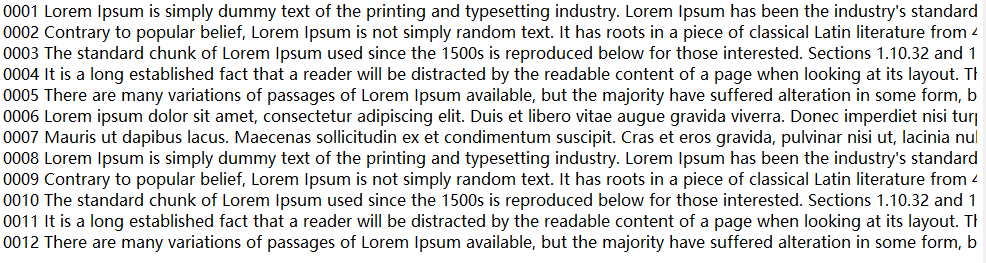

Each line has a line number, followed by a line of words, as shown above.
please emit a sequence of <word, line number> pairs. The reduce and additional transformations accept all pairs for a given word, sort the corresponding line numbers, and emits a <word, list(line numbers)> pair. The set of all the output pairs forms a simple inverted index.

The output is like:
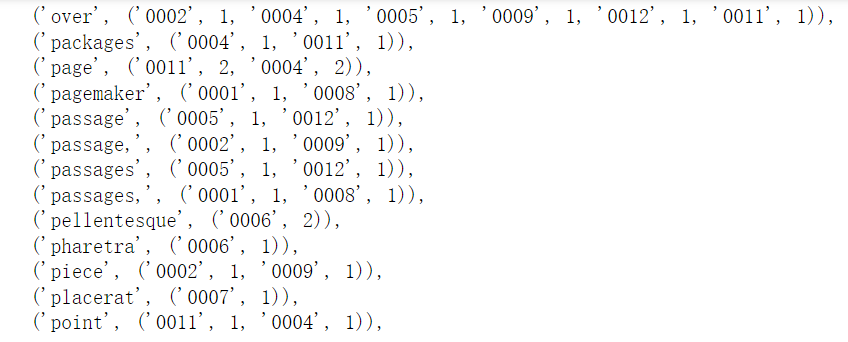

## Question 3 (optional) What if there is no line number in a text file, how to create the inverted index above?